# HW2 Part 1 — Data Cleaning & Validation

**Input:** `ohlc_hw` in `data/data.db` (raw, intentionally dirty, never modified).
**Output:** `ohlc_hw_cleaned` plus three audit tables in the same local database:

| table | contents |
|---|---|
| `ohlc_hw_cleaned` | unique, validated observations with repair and review flags |
| `ohlc_hw_quarantine` | rows withheld from the cleaned table, with their **original** values and the reason |
| `ohlc_hw_repair_audit` | one row per changed cell: original value, repaired value, reason, method, evidence |
| `ohlc_hw_ticker_audit` | every raw ticker label and the normalized ticker it maps to |
| `ohlc_hw_removed` | every removed row (exact duplicates, all-price-missing rows) with its original values and the `source_rowid` of the copy that was kept |
| `ohlc_hw_quality_diagnosis` | the complete pre-repair Data Quality Report |

The detection, repair and validation logic lives in `hw2_cleaning.py` and is unit-tested in `tests/` (run `pytest tests`).
This notebook applies it to the real data and documents each decision with the evidence behind it.

The reference table `ohlc` is used for exactly two things: each ticker's **expected trading dates**, and **date-matched adjustment factors** for adjusted close. It never replaces the delivery's raw prices.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import hw2_cleaning as hc

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

DB_PATH = Path("data/data.db")
assert DB_PATH.exists(), f"database not found at {DB_PATH.resolve()}"

counts_before = hc.table_counts(DB_PATH)
fingerprints_before = {t: hc.table_fingerprint(DB_PATH, t) for t in ["ohlc_hw", "ohlc"]}
counts_before

market_caps                    4342
ohlc                         368251
ohlc_hw                      397711
ohlc_hw_cleaned              368246
ohlc_hw_quality_diagnosis    114138
ohlc_hw_quarantine                5
ohlc_hw_removed               29460
ohlc_hw_repair_audit          28808
ohlc_hw_ticker_audit            150
Name: rows, dtype: int64

## 1.1 Load and inspect

The raw table is read through a read-only SQLite connection. SQLite's `rowid` is kept as `source_rowid`
so every quarantined or repaired row can be traced back to the exact raw record.

In [2]:
raw = hc.load_table(DB_PATH, "ohlc_hw", with_rowid=True)
reference = hc.load_table(DB_PATH, "ohlc")
print(f"ohlc_hw: {len(raw):,} rows | ohlc (reference): {len(reference):,} rows")
raw.info()

ohlc_hw: 397,711 rows | ohlc (reference): 368,251 rows
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397711 entries, 0 to 397710
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   source_rowid  397711 non-null  int64  
 1   ts            397711 non-null  object 
 2   open          397711 non-null  float64
 3   high          397711 non-null  float64
 4   low           397711 non-null  float64
 5   close         397711 non-null  float64
 6   adj_close     377856 non-null  float64
 7   volume        397711 non-null  int64  
 8   ticker        397711 non-null  object 
dtypes: float64(5), int64(2), object(2)
memory usage: 27.3+ MB


In [3]:
raw.drop(columns="source_rowid").describe().T

,count,mean,std,min,25%,50%,75%,max
open,397711.0,4.628548e+01,6.713259e+01,0.000000,4.209938e+00,19.85,57.53,6.042600e+02
high,397711.0,4.674766e+01,6.777821e+01,0.005208,4.240000e+00,20.06,58.13,6.086300e+02
low,397711.0,4.581628e+01,6.647718e+01,0.004801,4.160000e+00,19.63,56.95,5.978800e+02
close,397711.0,4.629290e+01,6.714188e+01,0.005208,4.200000e+00,19.86,57.53,6.054000e+02
adj_close,377856.0,5.165225e+01,1.945840e+02,0.002945,1.390000e+00,11.96,43.77,1.044251e+04
volume,397711.0,3.097773e+07,1.266237e+08,0.000000,1.730700e+06,4648200.00,11023796.50,9.276606e+09


| column | meaning |
|---|---|
| `ts` | observation (trading) date, stored as text `YYYY-MM-DD` |
| `ticker` | vendor ticker label — may contain HTML markup |
| `open`, `high`, `low`, `close` | raw daily prices (split-adjusted by the vendor, not dividend-adjusted) |
| `adj_close` | vendor adjusted close (splits **and** dividends) — used for returns in Part 2 |
| `volume` | shares traded |

`describe()` already shows two warning signs: `open` has a minimum of **0** and `adj_close` reaches **10,442** while the largest raw close is 605.

In [4]:
print("ts formats:", raw["ts"].str.replace(r"\d", "9", regex=True).value_counts().to_dict())
print(f"date range: {raw['ts'].min()} to {raw['ts'].max()}")
print(f"raw ticker labels: {raw['ticker'].nunique()}")
raw["ticker"].value_counts().head(8)

ts formats: {'9999-99-99': 397711}
date range: 1962-01-02 to 2024-12-06
raw ticker labels: 150


ticker
PG     15450
MRK    15442
IBM    15433
DIS    15420
JNJ    15399
KO     15385
CAT    15352
CVX    15349
Name: count, dtype: int64

## 1.2 Detect data-quality issues

### Ticker labels
Labels are normalized **before** any grouping or de-duplication: strip HTML tags and entities, trim whitespace, upper-case.
The audit table keeps every raw label and the ticker it maps to.

In [5]:
normalized, ticker_audit = hc.normalize_tickers(raw)
print(f"{ticker_audit['ticker_raw'].nunique()} raw labels -> {ticker_audit['normalized_ticker'].nunique()} tickers")
print("label styles:", raw["ticker"].str.extract(r"(<span[^>]*>)")[0].fillna("(plain)").value_counts().to_dict())
print(ticker_audit[["markup_removed", "whitespace_stripped", "case_changed"]].sum().to_dict())
print("tickers:", sorted(ticker_audit["normalized_ticker"].unique()))
ticker_audit[ticker_audit["normalized_ticker"] == "AAPL"]

150 raw labels -> 30 tickers
label styles: {'(plain)': 357775, '<span style="color: red">': 10088, '<span style="font-weight: bold; color: red">': 10041, '<span style="color: blue">': 9916, '<span style="font-weight: bold; color: blue">': 9891}
{'markup_removed': 120, 'whitespace_stripped': 0, 'case_changed': 0}
tickers: ['AAPL', 'AMGN', 'AMZN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'GS', 'HD', 'HON', 'IBM', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'NVDA', 'PG', 'SHW', 'TRV', 'UNH', 'V', 'VZ', 'WMT']


,ticker_raw,normalized_ticker,n_rows,markup_removed,whitespace_stripped,case_changed
0,"<a target=""_blank""><span style=""color: blue"">AAPL</span></a>",AAPL,307,True,False,False
1,"<a target=""_blank""><span style=""color: red"">AAPL</span></a>",AAPL,318,True,False,False
2,"<a target=""_blank""><span style=""font-weight: bold; color: blue"">AAPL</span></a>",AAPL,306,True,False,False
3,"<a target=""_blank""><span style=""font-weight: bold; color: red"">AAPL</span></a>",AAPL,264,True,False,False
4,AAPL,AAPL,10747,False,False,False


Every label is either plain or wrapped in one of four HTML styles; there are no whitespace or case variants, but the normalizer handles them anyway (see tests). All 30 tickers match the reference table.

### Duplicate `(ticker, ts)` keys
An **exact duplicate** repeats every value of another row after ticker normalization. A **conflicting duplicate** shares the key but differs in some value — those are never resolved by keeping an arbitrary row; all copies are quarantined.

In [6]:
kept, exact_copies = hc.split_exact_duplicates(normalized)
unique, conflicts = hc.split_conflicting_keys(kept)
unique = unique.sort_values(["ticker", "ts"])  # date order within each ticker for all later checks
print(f"exact duplicate rows removed: {len(exact_copies):,}")
print(f"keys with conflicting values: {conflicts[['ticker', 'ts']].drop_duplicates().shape[0]}")
print(f"unique observations: {len(unique):,}")
print("copies per duplicated key:", normalized[normalized.duplicated(hc.KEY, keep=False)]
      .groupby(hc.KEY).size().value_counts().to_dict())
print("duplicates also share the raw label:", normalized.duplicated(["ticker_raw", "ts"]).sum() == len(exact_copies))

exact duplicate rows removed: 29,460
keys with conflicting values: 0
unique observations: 368,251
copies per duplicated key: {2: 29460}
duplicates also share the raw label: True


All 29,460 repeated keys are exact copies (each appears exactly twice with the same raw label), so the conflict check correctly finds **zero** conflicts.
The detector is demonstrated on a deliberately injected conflict, which the cleaner quarantines in full:

In [7]:
demo = pd.DataFrame({
    "ts": ["2024-01-02", "2024-01-02", "2024-01-03", "2024-01-03"],
    "ticker": ["DEMO", "<b>DEMO</b>", "DEMO", "DEMO"],
    "open": [10.0, 10.0, 11.0, 11.0], "high": [10.5, 10.5, 11.5, 11.5],
    "low": [9.5, 9.5, 10.5, 10.5], "close": [10.0, 10.0, 11.0, 11.2],
    "adj_close": [5.0, 5.0, 5.5, 5.6], "volume": [100, 100, 100, 100],
})
demo_norm, _ = hc.normalize_tickers(demo)
demo_kept, demo_copies = hc.split_exact_duplicates(demo_norm)
_, demo_conflicts = hc.split_conflicting_keys(demo_kept)
print(f"exact copies: {len(demo_copies)}, conflicting rows: {len(demo_conflicts)}")
demo_conflicts[["ticker_raw", "ticker", "ts", "close", "adj_close"]]

exact copies: 1, conflicting rows: 2


,ticker_raw,ticker,ts,close,adj_close
2,DEMO,DEMO,2024-01-03,11.0,5.5
3,DEMO,DEMO,2024-01-03,11.2,5.6


All later diagnostics run on the **normalized, de-duplicated** observations so that counts are not doubled.

### Missing values
Missing cells (a value absent from an existing row) and missing trading dates (an absent row) are separate checks.

In [8]:
pd.concat({"raw table": hc.missing_value_summary(normalized), "after de-duplication": hc.missing_value_summary(unique)}, axis=1)

raw table           after de-duplication          
            missing     share              missing     share
open              0  0.000000                    0  0.000000
high              0  0.000000                    0  0.000000
low               0  0.000000                    0  0.000000
close             0  0.000000                    0  0.000000
adj_close     19855  0.049923                18374  0.049895
volume            0  0.000000                    0  0.000000

In [9]:
by_ticker = hc.missing_by_ticker(unique)
print(f"tickers with missing adj_close: {len(by_ticker)} of {unique['ticker'].nunique()}")
by_ticker["adj_close"].describe()[["min", "50%", "max"]]

tickers with missing adj_close: 30 of 30


min    228.0
50%    657.5
max    831.0
Name: adj_close, dtype: float64

Only `adj_close` is ever missing (19,855 cells in the raw table, 18,374 after removing copies), spread across all 30 tickers.
Raw OHLC and volume have **no** missing cells, so the "drop rows with all prices missing", "forward-fill prices" and "fill volume with 0" repairs have nothing to do on this delivery; they are demonstrated on injected data in section 1.3.

The missing-cell detector is demonstrated on an injected bar with a missing close and missing volume. Each missing cell becomes its own Data Quality Report row; a missing raw price is graded `high` because no return or bound check is possible without it.

In [10]:
missing_demo = pd.DataFrame({
    "ticker": "DEMO", "ts": ["2024-03-01", "2024-03-04", "2024-03-05"],
    "open": [20.0, 20.4, 20.6], "high": [20.5, 20.9, 21.0], "low": [19.8, 20.1, 20.3],
    "close": [20.2, np.nan, 20.8], "adj_close": [10.1, 10.3, np.nan], "volume": [500.0, np.nan, 700.0],
})
display(hc.missing_value_summary(missing_demo).T)
demo_issues = hc.build_quality_report(missing_demo, missing_demo[["ticker", "ts"]])
display(demo_issues[demo_issues["issue_type"].str.startswith("missing")])
assert (demo_issues["issue_type"] == "missing_raw_price").sum() == 1

,open,high,low,close,adj_close,volume
missing,0.0,0.0,0.0,1.000000,1.000000,1.000000
share,0.0,0.0,0.0,0.333333,0.333333,0.333333


,ticker,issue_type,issue_date,description,severity
0,DEMO,missing_raw_price,2024-03-04,close is missing,high
1,DEMO,missing_volume,2024-03-04,volume is missing,medium
2,DEMO,missing_adj_close,2024-03-05,adj_close is missing,medium


### Missing trading dates
Business weekdays include exchange holidays, so they are **not** used as the calendar. Instead, each ticker's dates in the supplied `ohlc` table are its expected sessions over its own history (the assignment's accepted reference calendar).

In [11]:
calendar = reference[["ticker", "ts"]]
gap_summary = hc.missing_dates_summary(unique, calendar)
for message in gap_summary["message"]:
    print(message)
print(f"\n{len(gap_summary)} tickers; total missing trading days in the source delivery: {gap_summary['missing_days'].sum()}")
assert len(gap_summary) == 30

Ticker AAPL is missing 0 trading days between 1980-12-12 and 2024-10-18
Ticker AMGN is missing 0 trading days between 1983-06-17 and 2024-10-18
Ticker AMZN is missing 0 trading days between 1997-05-15 and 2024-12-06
Ticker AXP is missing 0 trading days between 1972-04-03 and 2024-10-18
Ticker BA is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker CAT is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker CRM is missing 0 trading days between 2004-06-23 and 2024-10-18
Ticker CSCO is missing 0 trading days between 1990-02-16 and 2024-10-18
Ticker CVX is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticker DIS is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticker GS is missing 0 trading days between 1999-05-04 and 2024-10-18
Ticker HD is missing 0 trading days between 1981-09-22 and 2024-10-18
Ticker HON is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker IBM is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticke

Zero missing dates is the correct answer here — the de-duplicated delivery covers exactly the reference keys. To show the detector works, one date is deliberately removed from a copy of AAPL:

In [12]:
aapl = unique[unique["ticker"] == "AAPL"]
removed_date = aapl["ts"].iloc[100]
aapl_with_gap = aapl[aapl["ts"] != removed_date]
print(hc.missing_dates_summary(aapl_with_gap, calendar)["message"].item())
print("detected:", hc.find_missing_dates(aapl_with_gap, calendar)["ts"].tolist(), "| removed:", removed_date)
assert hc.find_missing_dates(aapl_with_gap, calendar)["ts"].tolist() == [removed_date]

Ticker AAPL is missing 1 trading days between 1980-12-12 and 2024-10-18
detected: ['1981-05-07'] | removed: 1981-05-07


### Outliers: 3-sigma daily returns
Simple raw-close returns `(close - prev_close) / prev_close` are computed within each ticker after sorting by date.
A return is flagged when `|return - mean| > 3 * std` with the **sample** standard deviation (`ddof=1`), both tails.
Undefined returns (first row, invalid close) are excluded; a ticker with fewer than two returns or zero standard deviation gets an explicit status and no flags.
This is a **review flag**, not a deletion rule.

In [13]:
return_stats = hc.ticker_return_stats(unique)
print("status counts:", return_stats["status"].value_counts().to_dict())
outliers = hc.flag_return_outliers(unique)
print(f"3-sigma flags: {outliers['is_outlier'].sum():,} "
      f"({outliers['is_outlier'].mean():.2%} of rows; a normal distribution would give ~0.27%)")
flag_counts = outliers.groupby("ticker")["is_outlier"].sum()
print("flags per ticker: min", flag_counts.min(), "median", int(flag_counts.median()), "max", flag_counts.max())
outliers.loc[outliers["is_outlier"]].assign(abs_ret=lambda d: d["return"].abs()).nlargest(8, "abs_ret")[
    ["ticker", "ts", "return", "mean", "std"]]

status counts: {'ok': 30}


3-sigma flags: 5,056 (1.37% of rows; a normal distribution would give ~0.27%)
flags per ticker: min 67 median 179 max 228


,ticker,ts,return,mean,std
384157,TRV,1976-10-28,1.000000,0.000573,0.024232
146175,TRV,1981-08-10,1.000000,0.000573,0.024232
8975,TRV,1978-12-20,0.997512,0.000573,0.024232
379437,MCD,1968-01-02,-0.753620,0.000678,0.018524
110212,AAPL,2000-09-29,-0.518695,0.001074,0.027846
148374,TRV,1981-08-11,-0.500000,0.000573,0.024232
273517,TRV,1976-10-29,-0.491323,0.000573,0.024232
273555,TRV,1978-12-21,-0.490660,0.000573,0.024232


Daily equity returns are fat-tailed, so ~1.4% of days exceeding 3 sample standard deviations is expected and most flags are ordinary large market moves (e.g. 1987-10-19 appears for many tickers). The largest moves are investigated below rather than repaired automatically.

Every real ticker has status `ok`, so the degenerate cases are demonstrated on injected data: a ticker whose price never changes (zero sample standard deviation) and a ticker with a single return. Neither can produce a 3-sigma flag; without the explicit status, `|r - mean| > 3 * 0` would wrongly flag nothing or everything depending on rounding.

In [14]:
flat = pd.DataFrame({"ticker": "FLAT", "ts": pd.bdate_range("2024-01-02", periods=6).strftime("%Y-%m-%d"),
                     "close": 25.0})
short = pd.DataFrame({"ticker": "SHORT", "ts": ["2024-01-02", "2024-01-03"], "close": [10.0, 30.0]})
degenerate = pd.concat([flat, short], ignore_index=True)
display(hc.ticker_return_stats(degenerate))
degenerate_flags = hc.flag_return_outliers(degenerate)
print("3-sigma flags:", int(degenerate_flags["is_outlier"].sum()))
assert not degenerate_flags["is_outlier"].any()

,n_returns,mean,std,status
ticker,,,,
FLAT,5,0.0,0.0,zero_std
SHORT,1,2.0,NaN,insufficient_returns


3-sigma flags: 0


### Invalid prices and impossible OHLC relationships

In [15]:
invalid = hc.detect_invalid_prices(unique)
bounds = hc.detect_ohlc_inconsistencies(unique)
print("invalid prices:", invalid["issue_type"].value_counts().to_dict())
print("OHLC relationship issues:", bounds["issue_type"].value_counts().to_dict())
first_dates = unique.groupby("ticker")["ts"].min()
zero_open = unique[unique["open"] <= 0][["ticker", "ts", "open", "high", "low", "close", "adj_close", "volume"]]
zero_open.assign(first_row_of_ticker=zero_open["ts"].values == first_dates.loc[zero_open["ticker"]].values)

invalid prices: {'nonpositive_price': 5}
OHLC relationship issues: {'open_outside_range': 5}


,ticker,ts,open,high,low,close,adj_close,volume,first_row_of_ticker
287343,CVX,1962-01-02,0.0,3.30000,3.24000,3.30000,0.335750,105840,True
350808,JNJ,1962-01-02,0.0,0.22338,0.22222,0.22338,0.064012,0,True
224790,MCD,1966-07-05,0.0,0.27366,0.26749,0.26955,0.118090,388800,True
364568,MRK,1962-01-02,0.0,0.39703,0.39317,0.39537,0.068447,633830,True
99637,PG,1962-01-02,0.0,1.44000,1.42000,1.43000,0.259300,192000,True


The only invalid prices are five `open = 0` values, and they are also the only bounds violations (`low > open`). Each is the **first** observation of its ticker, so there is no earlier price to carry forward. There are no non-finite values, no `high < close`, no `low > close` and no `high < low`.
The detectors are demonstrated on injected rows covering every case, including adjusted close (which is checked for positivity but not bound by raw high/low):

In [16]:
injected = pd.DataFrame({
    "ticker": "DEMO", "ts": ["2024-01-02", "2024-01-03", "2024-01-04", "2024-01-05", "2024-01-08", "2024-01-09"],
    "open":  [10.0, 10.0, 12.0, 10.0, 10.0, 10.0],
    "high":  [ 9.5, 10.5, 10.5,  9.0, 10.5, 10.5],
    "low":   [ 9.0, 10.2,  9.5, 11.0,  9.5,  9.5],
    "close": [ 9.2, 10.0, 10.0, 10.0, -1.0, 10.0],
    "adj_close": [5.0, 5.0, 5.0, 5.0, 5.0, np.inf],
    "volume": [100, 100, 100, 100, 0, 100],
})
pd.concat([hc.detect_ohlc_inconsistencies(injected), hc.detect_invalid_prices(injected),
           hc.detect_volume_issues(injected)]).sort_values("issue_date")

,ticker,issue_type,issue_date,description,severity
4,DEMO,open_outside_range,2024-01-02,"open outside [low, high]: O=10.0 H=9.5 L=9.0 C=9.2",high
1,DEMO,low_above_close,2024-01-03,low > close: O=10.0 H=10.5 L=10.2 C=10.0,high
5,DEMO,open_outside_range,2024-01-03,"open outside [low, high]: O=10.0 H=10.5 L=10.2 C=10.0",high
6,DEMO,open_outside_range,2024-01-04,"open outside [low, high]: O=12.0 H=10.5 L=9.5 C=10.0",high
0,DEMO,high_below_close,2024-01-05,high < close: O=10.0 H=9.0 L=11.0 C=10.0,high
2,DEMO,low_above_close,2024-01-05,low > close: O=10.0 H=9.0 L=11.0 C=10.0,high
7,DEMO,open_outside_range,2024-01-05,"open outside [low, high]: O=10.0 H=9.0 L=11.0 C=10.0",high
8,DEMO,high_below_low,2024-01-05,high < low: O=10.0 H=9.0 L=11.0 C=10.0,high
3,DEMO,low_above_close,2024-01-08,low > close: O=10.0 H=10.5 L=9.5 C=-1.0,high
0,DEMO,nonpositive_price,2024-01-08,close = -1.0 (must be > 0),high


### Zero volume and weekend dates

In [17]:
zero_vol = unique[unique["volume"] == 0]
flat = (zero_vol["open"] == zero_vol["high"]) & (zero_vol["high"] == zero_vol["low"]) & (zero_vol["low"] == zero_vol["close"])
print(f"zero-volume rows: {len(zero_vol)} | by ticker: {zero_vol['ticker'].value_counts().to_dict()}")
print(f"years: {zero_vol['ts'].str[:4].astype(int).min()}-{zero_vol['ts'].str[:4].astype(int).max()} | O=H=L=C on {flat.mean():.0%} of them")
print("same rows in reference:", int((reference["volume"] == 0).sum()))

weekend = hc.detect_weekend_dates(unique)
print(f"\nweekend-dated rows: {len(weekend)} | tickers: {weekend['ticker'].nunique()} | "
      f"{weekend['issue_date'].min()} to {weekend['issue_date'].max()}")
print("day names:", pd.to_datetime(weekend["issue_date"]).dt.day_name().value_counts().to_dict())

zero-volume rows: 75 | by ticker: {'WMT': 52, 'JNJ': 11, 'IBM': 3, 'TRV': 3, 'HON': 2, 'AXP': 1, 'MRK': 1, 'NKE': 1, 'SHW': 1}
years: 1962-1982 | O=H=L=C on 96% of them
same rows in reference: 75



weekend-dated rows: 384 | tickers: 16 | 1974-01-06 to 1975-04-20
day names: {'Sunday': 384}


In [18]:
axp_dates = set(unique.loc[unique["ticker"] == "AXP", "ts"])
sundays = sorted(weekend.loc[weekend["ticker"] == "AXP", "issue_date"])
friday_present = [(pd.Timestamp(d) - pd.Timedelta(days=2)).strftime("%Y-%m-%d") in axp_dates for d in sundays]
print(f"AXP: {len(sundays)} Sunday rows; the preceding Friday exists for only {sum(friday_present)} of them")

AXP: 24 Sunday rows; the preceding Friday exists for only 2 of them


Zero volume occurs on 75 old (1962–1982) bars, mostly flat O=H=L=C — consistent with stale or untraded quotes. Volume is never missing, so nothing is filled; these rows are kept and flagged.

The 384 Sunday-dated rows (16 tickers, 1974-01 to 1975-04) are in the reference table too. Because the preceding Friday is usually absent, they look like Friday sessions recorded under the wrong date — but that cannot be proven from this data, so **dates are not changed**; the rows are kept and flagged.

### Isolated price spikes (confirmed errors)
A raw close is treated as a **confirmed** one-day error only when all of these hold: both neighbours exist and are valid with positive volume; the close is more than 40% away from **both** neighbours in the same direction; the two neighbours agree within 5%; and the row itself reports zero volume.

In [19]:
spikes = hc.find_isolated_price_spikes(unique)
spikes[["ticker", "ts", "open", "high", "low", "close", "volume", "prev_ts", "prev_close", "next_ts", "next_close", "move_vs_prev", "move_vs_next"]]

,ticker,ts,open,high,low,close,volume,prev_ts,prev_close,next_ts,next_close,move_vs_prev,move_vs_next
384157,TRV,1976-10-28,9.22,9.22,9.22,9.22,0,1976-10-27,4.61,1976-10-29,4.69,1.000000,0.965885
8975,TRV,1978-12-20,8.03,8.03,8.03,8.03,0,1978-12-19,4.02,1978-12-21,4.09,0.997512,0.963325
146175,TRV,1981-08-10,12.06,12.06,12.06,12.06,0,1981-08-07,6.03,1981-08-11,6.03,1.000000,1.000000


Exactly three rows qualify, all TRV. The neighbouring observations and adjustment factors (`adj_close / close`) from both the delivery and the reference:

In [20]:
ref_adj = reference.rename(columns={"adj_close": "ref_adj_close"})[["ticker", "ts", "ref_adj_close"]]
trv = unique[unique["ticker"] == "TRV"].merge(ref_adj, on=["ticker", "ts"]).reset_index(drop=True)
trv["factor"] = trv["adj_close"] / trv["close"]
trv["ref_factor"] = trv["ref_adj_close"] / trv["close"]
for date in spikes["ts"]:
    i = trv.index[trv["ts"] == date][0]
    display(trv.loc[i - 2:i + 2, ["ts", "open", "high", "low", "close", "volume", "adj_close", "ref_adj_close", "factor", "ref_factor"]])

,ts,open,high,low,close,volume,adj_close,ref_adj_close,factor,ref_factor
1150,1976-10-26,4.50,4.50,4.50,4.50,91200,0.95719,0.95719,0.212709,0.212709
1151,1976-10-27,4.61,4.61,4.61,4.61,230400,13.88325,0.98046,3.011551,0.212681
1152,1976-10-28,9.22,9.22,9.22,9.22,0,NaN,3.21000,NaN,0.348156
1153,1976-10-29,4.69,4.69,4.69,4.69,79200,0.99707,0.99707,0.212595,0.212595
1154,1976-11-01,4.66,4.66,4.66,4.66,59200,0.99043,0.99043,0.212539,0.212539


,ts,open,high,low,close,volume,adj_close,ref_adj_close,factor,ref_factor
1691,1978-12-18,4.02,4.02,4.02,4.02,155200,0.90645,0.90645,0.225485,0.225485
1692,1978-12-19,4.02,4.02,4.02,4.02,72000,0.90645,0.90645,0.225485,0.225485
1693,1978-12-20,8.03,8.03,8.03,8.03,0,2.80000,2.80000,0.348692,0.348692
1694,1978-12-21,4.09,4.09,4.09,4.09,105600,0.92409,0.92409,0.225939,0.225939
1695,1978-12-22,4.09,4.09,4.09,4.09,91200,0.93696,0.93696,0.229086,0.229086


,ts,open,high,low,close,volume,adj_close,ref_adj_close,factor,ref_factor
2356,1981-08-06,6.06,6.06,6.06,6.06,60000,1.58,1.58,0.260726,0.260726
2357,1981-08-07,6.03,6.03,6.03,6.03,264800,1.57,1.57,0.260365,0.260365
2358,1981-08-10,12.06,12.06,12.06,12.06,0,4.20,4.20,0.348259,0.348259
2359,1981-08-11,6.03,6.03,6.03,6.03,24800,1.57,1.57,0.260365,0.260365
2360,1981-08-12,6.13,6.13,6.13,6.13,267200,1.59,1.59,0.259380,0.259380


**Evidence.** On each date the whole bar sits at ~2x both neighbours, with zero volume, and reverses completely the next day; neighbours are ordinary bars with positive volume. These are isolated recording errors.

**The reference factor is also wrong on these dates** (~0.348 versus ~0.21–0.26 either side), so the reference cannot supply a trusted adjusted close there. The factors on either side agree closely (0.212681 / 0.212595, 0.225485 / 0.225939, 0.260365 / 0.260365), so no dividend or split falls between them.

Other large moves are **not** confirmed errors and are kept with their 3-sigma flag:

In [21]:
for ticker, date in [("AAPL", "2000-09-29"), ("MCD", "1968-01-02")]:
    t = unique[unique["ticker"] == ticker].reset_index(drop=True)
    i = t.index[t["ts"] == date][0]
    display(t.loc[i - 2:i + 2, ["ticker", "ts", "open", "high", "low", "close", "adj_close", "volume"]])

,ticker,ts,open,high,low,close,adj_close,volume
4997,AAPL,2000-09-27,0.92411,0.94196,0.86161,0.87388,0.73797,402259544
4998,AAPL,2000-09-28,0.88058,0.96094,0.85937,0.95536,0.80677,980466003
4999,AAPL,2000-09-29,0.50335,0.51786,0.45313,0.45982,0.38831,3128875900
5000,AAPL,2000-10-02,0.47321,0.47768,0.41964,0.43304,0.36569,2424791671
5001,AAPL,2000-10-03,0.44531,0.44643,0.39621,0.39844,NaN,2038122484


,ticker,ts,open,high,low,close,adj_close,volume
374,MCD,1967-12-28,0.74074,0.74897,0.73868,0.73868,0.323630,194400
375,MCD,1967-12-29,0.73868,0.74074,0.70988,0.70988,0.311000,1093500
376,MCD,1968-01-02,0.17490,0.17490,0.17490,0.17490,0.075921,6755143
377,MCD,1968-01-03,0.17567,0.17567,0.17567,0.17567,0.076256,3839207
378,MCD,1968-01-04,0.16204,0.16204,0.16204,0.16204,0.070339,10545887


* **AAPL 2000-09-29 (−52%)**: the new level persists, the intraday range is consistent and volume is ~3x the prior day. This looks like a genuine market move; no external source was consulted, so no specific news event is claimed.
* **MCD 1968-01-02 (−75%)**: raw and adjusted close both drop and stay at the new level. It could be an unadjusted corporate action or a splice in the vendor history; there is no evidence in the data to decide. It is kept and flagged — a stated uncertainty rather than a guessed repair.

### Adjusted-close anomalies
Dividend adjustments move the factor `adj_close / close` by fractions of a percent. Each row's factor is compared with the ticker's centred 11-day rolling median; a deviation above 10% is anomalous. This screen uses only the delivery itself, and is then cross-checked against the date-matched reference value.

In [22]:
factor, deviation = hc.adj_factor_deviation(unique)
anomalous = deviation.abs() > hc.FACTOR_TOL
check = unique[hc.KEY + ["close", "adj_close"]].merge(ref_adj, on=hc.KEY, how="left").set_index(unique.index)
mismatch = unique["adj_close"].notna() & ~np.isclose(unique["adj_close"], check["ref_adj_close"], rtol=hc.REFERENCE_RTOL)
print(f"factor anomalies (self-screen): {anomalous.sum():,}")
print(f"adj_close differs from reference: {mismatch.sum():,}")
print(f"both: {(anomalous & mismatch).sum():,} | mismatch missed by screen: {(mismatch & ~anomalous).sum()} | "
      f"anomalous but equal to reference: {(anomalous & ~mismatch).sum()}")
ratio = (unique["adj_close"] / check["ref_adj_close"])[mismatch]
print("vendor / reference ratio on mismatches:", ratio.quantile([0, 0.5, 1]).round(2).to_dict())

factor anomalies (self-screen): 10,423
adj_close differs from reference: 10,417
both: 10,417 | mismatch missed by screen: 0 | anomalous but equal to reference: 6
vendor / reference ratio on mismatches: {0.0: 4.0, 0.5: 14.06, 1.0: 24.0}


In [23]:
unique.loc[anomalous & ~mismatch, hc.KEY + ["close", "adj_close"]].assign(deviation=deviation[anomalous & ~mismatch])

,ticker,ts,close,adj_close,deviation
369881,AAPL,1990-10-19,0.28000,0.280000,0.256054
168515,KO,1962-01-02,0.26302,0.048145,-0.204933
381720,NKE,1981-08-10,0.15234,0.107230,0.262257
262069,SHW,1982-02-12,0.39323,0.206950,0.115402
8975,TRV,1978-12-20,8.03000,2.800000,0.523269
146175,TRV,1981-08-10,12.06000,4.200000,0.339109


* **10,417 corrupted values**: every one is 4x–24x the reference and is caught independently by the self-screen — two independent pieces of evidence.
* **6 rows where vendor and reference share the same anomalous factor**: the 2 TRV spike dates, plus AAPL 1990-10-19, NKE 1981-08-10 and SHW 1982-02-12 (one-day factor jumps of 11–26% that revert next day while raw prices look normal), and KO 1962-01-02 — the first KO row, where there is no earlier neighbour to confirm it is isolated.

### Data Quality Report
All detectors combined, one row per issue per observation (an observation can have several). This is the diagnosis **before** any repair and is retained unchanged.

In [24]:
pre_dedup = hc.label_and_duplicate_issues(normalized, exact_copies, conflicts)
quality_report = hc.build_quality_report(unique, calendar, reference, pre_dedup)
diagnosis = quality_report.copy()
print(f"{len(quality_report):,} issue rows")
summary = (quality_report.groupby(["severity", "issue_type"])
           .agg(issues=("ticker", "size"), tickers=("ticker", "nunique")).reset_index())
summary["severity"] = pd.Categorical(summary["severity"], ["high", "medium", "low"], ordered=True)
summary.sort_values(["severity", "issues"], ascending=[True, False]).reset_index(drop=True)

114,138 issue rows


,severity,issue_type,issues,tickers
0,high,adj_factor_anomaly,10423,30
1,high,adj_close_reference_mismatch,10417,30
2,high,nonpositive_price,5,5
3,high,open_outside_range,5,5
4,high,isolated_price_spike,3,1
5,medium,missing_adj_close,18374,30
6,medium,return_outlier_3sd,5056,30
7,medium,weekend_date,384,16
8,low,ticker_markup,39936,30
9,low,exact_duplicate,29460,30


In [25]:
quality_report.groupby("issue_type").head(1).reset_index(drop=True)

,ticker,issue_type,issue_date,description,severity
0,AAPL,ticker_markup,1980-12-19,"raw label '<a target=""_blank""><span style=""color: red"">AAPL</span></a>' normalized",low
1,AAPL,return_outlier_3sd,1980-12-26,simple return +9.23% vs ticker mean +0.107% (+3.3 sample std),medium
2,AAPL,exact_duplicate,1981-01-02,exact copy of another row after ticker normalization; removed,low
3,AAPL,missing_adj_close,1981-01-08,adj_close is missing,medium
4,AAPL,adj_close_reference_mismatch,1981-02-03,adj_close 1.26459 vs reference 0.0950693 (x13.30),high
5,AAPL,adj_factor_anomaly,1981-02-03,"adj_close/close = 10.25368, +1230% vs the ticker's rolling median factor",high
6,AXP,zero_volume,1972-12-14,volume = 0; possibly stale or untraded,low
7,AXP,weekend_date,1974-01-06,observation dated on a Sunday; date retained as delivered,medium
8,CVX,nonpositive_price,1962-01-02,open = 0.0 (must be > 0),high
9,CVX,open_outside_range,1962-01-02,"open outside [low, high]: O=0.0 H=3.3 L=3.24 C=3.3",high


**Severity choices**

| severity | issue types | why |
|---|---|---|
| high | `nonpositive_price`, `nonfinite_price`, `missing_raw_price`, OHLC bound violations, `conflicting_duplicate`, `isolated_price_spike`, `adj_factor_anomaly`, `adj_close_reference_mismatch`, `invalid_volume` | the value is impossible or demonstrably wrong; using it would corrupt returns or risk metrics |
| medium | `missing_adj_close`, `missing_volume`, `missing_trading_date`, `return_outlier_3sd`, `weekend_date` | information is absent or suspicious but may be legitimate; needs a documented repair or a review |
| low | `exact_duplicate`, `ticker_markup`, `zero_volume` | formatting or redundancy that is fully resolved by normalization / de-duplication, or a plausible stale quote |

## 1.3 Clean the data

### Decisions

| issue | action | rationale |
|---|---|---|
| ticker markup | normalize; keep `ticker_raw` and the ticker audit table | identity must be fixed before grouping |
| exact duplicates | remove after normalization; save each removed row in `ohlc_hw_removed` | identical information; the kept row records `duplicate_copies_removed` and each removed row records `duplicate_of_source_rowid` |
| conflicting keys | quarantine **all** copies | no basis to prefer one (none found) |
| missing ticker or unparseable date | quarantine with the delivered `ts_raw` | a row without a key cannot be placed in a series (none found) |
| all raw prices missing | drop before filling | nothing to repair (none found) |
| nonpositive / non-finite raw price | blank the cell → forward-fill within ticker → recheck bounds; quarantine if there is no earlier price or the fill breaks today's range (**Option 1**) | the 5 `open = 0` rows are leading rows → quarantined, never replaced with close |
| OHLC bound violation with all prices positive | quarantine | the faulty field cannot be identified, so no repair is defensible (none found) |
| confirmed isolated spike (TRV ×3) | linear interpolation of each raw field between the valid neighbours, then **immediate revalidation** of the repaired bar; quarantine if it is missing or out of bounds | confirmed error, valid neighbours on both sides, no extrapolation; only the confirmed rows are interpolated, other gaps go to forward-fill |
| missing raw price | forward-fill within ticker, flagged; leading gaps quarantined | assignment rule; never borrows another ticker's value (none found) |
| missing volume | fill 0 and flag `volume_filled` | unknown volume is not evidence of no trading (none found) |
| missing / corrupted `adj_close` | `close × factor` from the **date-matched reference factor**, only if the reference row's close equals ours and its factor is not itself anomalous; otherwise from the **neighbouring factors** if both exist and agree within 0.5%; otherwise quarantine | no factor is forward-filled across a possible corporate action |
| anomalous factor that cannot be confirmed (KO 1962-01-02) | keep, flag `adj_factor_review_flag` | not proven wrong; no evidence-based replacement |
| 3-sigma returns, zero volume, weekend dates | keep and flag | potentially legitimate; review flags, not deletion rules. All 3-sigma flags are classified in the investigation below; none is repaired on the 3-sigma evidence alone |

### Repair behaviour on injected examples
None of the missing-price, missing-volume or ambiguous-bounds cases occur in this delivery, so the cleaner is run on a small injected dataset that contains each of them:

In [26]:
def demo_bars(ticker, closes, start="2024-02-01"):
    closes = np.asarray(closes, dtype=float)
    return pd.DataFrame({"ts": pd.bdate_range(start, periods=len(closes)).strftime("%Y-%m-%d"), "ticker": ticker,
                         "open": closes, "high": closes * 1.01, "low": closes * 0.99, "close": closes,
                         "adj_close": closes * 0.5, "volume": 1_000.0})

a, b = demo_bars("DEMO_A", [10, 10.1, 10.2, 10.3, 10.4, 10.5]), demo_bars("DEMO_B", [50, 50.5, 51, 51.5, 52, 52.5])
demo_reference = pd.concat([a, b], ignore_index=True)
a.loc[1, "close"] = np.nan                            # missing price -> forward-fill
a.loc[2, ["open", "high", "low", "close"]] = np.nan   # all prices missing -> dropped
a.loc[3, "volume"] = np.nan                           # missing volume -> 0, flagged
a.loc[4, "adj_close"] = np.nan                        # missing adj_close -> reference factor
b.loc[0, "open"] = 0.0                                # leading invalid price -> quarantined
b.loc[3, "high"] = 50.0                               # high < close with valid prices -> quarantined
demo_raw = pd.concat([a, b], ignore_index=True)
demo_raw.insert(0, "source_rowid", range(1, len(demo_raw) + 1))

demo_result = hc.clean_ohlc(demo_raw, demo_reference)
print(demo_result.counts)
display(demo_result.cleaned[["ticker", "ts", "close", "adj_close", "volume", "price_repair_method",
                             "adj_close_source", "volume_filled"]])
display(demo_result.quarantine[["ticker", "ts", "open", "high", "close", "quarantine_reason", "detail"]])
display(demo_result.repair_audit[["ticker", "ts", "column", "original_value", "repaired_value", "reason", "method"]])
assert hc.validate_cleaned(demo_result.cleaned)["passed"].all()

{'input_rows': 12, 'removed_exact_duplicates': 0, 'removed_all_prices_missing': 1, 'quarantined': 2, 'retained': 9, 'retained_with_price_repair': 1, 'retained_with_adj_close_repair': 2, 'retained_with_volume_fill': 1}


,ticker,ts,close,adj_close,volume,price_repair_method,adj_close_source,volume_filled
0,DEMO_A,2024-02-01,10.0,5.00,1000,<NA>,vendor,False
1,DEMO_A,2024-02-02,10.0,5.00,1000,forward_fill_within_ticker,neighbor_factor,False
2,DEMO_A,2024-02-06,10.3,5.15,0,<NA>,vendor,True
3,DEMO_A,2024-02-07,10.4,5.20,1000,<NA>,reference_factor,False
4,DEMO_A,2024-02-08,10.5,5.25,1000,<NA>,vendor,False
5,DEMO_B,2024-02-02,50.5,25.25,1000,<NA>,vendor,False
6,DEMO_B,2024-02-05,51.0,25.50,1000,<NA>,vendor,False
7,DEMO_B,2024-02-07,52.0,26.00,1000,<NA>,vendor,False
8,DEMO_B,2024-02-08,52.5,26.25,1000,<NA>,vendor,False


,ticker,ts,open,high,close,quarantine_reason,detail
0,DEMO_B,2024-02-06,51.5,50.0,51.5,ohlc_bounds_violation,valid prices violate low <= open/close <= high; faulty field unknown
1,DEMO_B,2024-02-01,0.0,50.5,50.0,unresolved_leading_gap,no earlier observation to forward-fill open (original 0.0)


,ticker,ts,column,original_value,repaired_value,reason,method
0,DEMO_A,2024-02-02,close,NaN,10.0,missing,forward_fill_within_ticker
1,DEMO_A,2024-02-06,volume,NaN,0.0,missing,fill_zero_flagged
2,DEMO_A,2024-02-02,adj_close,5.05,5.0,raw_close_repaired,close_times_validated_factor
3,DEMO_A,2024-02-07,adj_close,NaN,5.2,missing,close_times_validated_factor


Each repair is visible: the missing close is carried from the previous DEMO_A day (it lies inside that day's range), and because the close changed its adjusted close is rebuilt from the agreeing neighbour factors; the all-missing row is dropped; volume is filled with a flagged 0; a missing adjusted close is rebuilt from the date-matched reference factor; and the two unrepairable DEMO_B rows are quarantined with their original values.

### Clean the real delivery

In [27]:
result = hc.clean_ohlc(raw, reference)
cleaned = result.cleaned
pd.Series(result.counts, name="rows").to_frame()

,rows
input_rows,397711
removed_exact_duplicates,29460
removed_all_prices_missing,0
quarantined,5
retained,368246
retained_with_price_repair,3
retained_with_adj_close_repair,28796
retained_with_volume_fill,0


In [28]:
c = result.counts
accounting = pd.DataFrame({
    "rows": [c["input_rows"], -c["removed_exact_duplicates"], -c["removed_all_prices_missing"], -c["quarantined"], c["retained"]],
}, index=["raw ohlc_hw rows", "removed: exact duplicates", "removed: all prices missing", "quarantined", "retained in ohlc_hw_cleaned"])
assert c["input_rows"] - c["removed_exact_duplicates"] - c["removed_all_prices_missing"] - c["quarantined"] == c["retained"]
accounting

,rows
raw ohlc_hw rows,397711
removed: exact duplicates,-29460
removed: all prices missing,0
quarantined,-5
retained in ohlc_hw_cleaned,368246


**Duplicate accounting.** Every removed copy is credited to exactly one surviving row (in the cleaned table or, had it been quarantined, the quarantine table), and every removed row points at the `source_rowid` of the copy that was kept. Copies whose `adj_close` is missing are included: the copy-to-kept mapping uses a group id, because joining on values never matches missing values.

In [29]:
removed = result.removed
dupes = removed[removed["removal_reason"] == "exact_duplicate"]
credited = int(cleaned["duplicate_copies_removed"].sum() + result.quarantine["duplicate_copies_removed"].sum())
survivors = pd.concat([cleaned["source_rowid"], result.quarantine["source_rowid"]])
print(f"removed exact copies: {len(dupes):,} | credited to surviving rows: {credited:,} | "
      f"copies with missing adj_close: {dupes['adj_close'].isna().sum():,}")
assert credited == len(dupes) == c["removed_exact_duplicates"]
assert dupes["duplicate_of_source_rowid"].isin(survivors).all()
removed.head(3)

removed exact copies: 29,460 | credited to surviving rows: 29,460 | copies with missing adj_close: 1,481


,source_rowid,ticker_raw,ticker,ts_raw,ts,open,high,low,close,adj_close,volume,removal_reason,duplicate_of_source_rowid
0,2983,DIS,DIS,2004-04-28,2004-04-28,23.71,23.91,23.56,23.91,19.35000,28115278,exact_duplicate,1103
1,3017,CAT,CAT,1962-10-16,1962-10-16,1.35,1.39,1.35,1.35,0.41218,225600,exact_duplicate,1603
2,4681,TRV,TRV,1975-06-02,1975-06-02,3.72,3.72,3.72,3.72,0.79101,292800,exact_duplicate,1009


**Quarantined rows** (original values preserved):

In [30]:
result.quarantine[["source_rowid", "ticker_raw", "ticker", "ts", "open", "high", "low", "close", "adj_close", "volume", "quarantine_reason", "detail"]]

,source_rowid,ticker_raw,ticker,ts,open,high,low,close,adj_close,volume,quarantine_reason,detail
0,287344,CVX,CVX,1962-01-02,0.0,3.30000,3.24000,3.30000,0.335750,105840,unresolved_leading_gap,no earlier observation to forward-fill open (original 0.0)
1,350809,JNJ,JNJ,1962-01-02,0.0,0.22338,0.22222,0.22338,0.064012,0,unresolved_leading_gap,no earlier observation to forward-fill open (original 0.0)
2,224791,MCD,MCD,1966-07-05,0.0,0.27366,0.26749,0.26955,0.118090,388800,unresolved_leading_gap,no earlier observation to forward-fill open (original 0.0)
3,364569,MRK,MRK,1962-01-02,0.0,0.39703,0.39317,0.39537,0.068447,633830,unresolved_leading_gap,no earlier observation to forward-fill open (original 0.0)
4,99638,PG,PG,1962-01-02,0.0,1.44000,1.42000,1.43000,0.259300,192000,unresolved_leading_gap,no earlier observation to forward-fill open (original 0.0)


**Repair audit** — one row per changed cell:

In [31]:
audit = result.repair_audit
audit.groupby(["column", "reason", "method"]).size().rename("cells").reset_index()

,column,reason,method,cells
0,adj_close,anomalous_factor_shared_with_reference,close_times_validated_factor,3
1,adj_close,corrupted_vendor_factor,close_times_validated_factor,10417
2,adj_close,missing,close_times_validated_factor,18373
3,adj_close,raw_close_repaired,close_times_validated_factor,3
4,close,isolated_price_spike,linear_interpolation_between_neighbours,3
5,high,isolated_price_spike,linear_interpolation_between_neighbours,3
6,low,isolated_price_spike,linear_interpolation_between_neighbours,3
7,open,isolated_price_spike,linear_interpolation_between_neighbours,3


In [32]:
audit[audit["ticker"].eq("TRV") & audit["ts"].isin(spikes["ts"])].sort_values(["ts", "column"])[
    ["ticker", "ts", "column", "original_value", "repaired_value", "reason", "method", "evidence"]]

,ticker,ts,column,original_value,repaired_value,reason,method,evidence
24974,TRV,1976-10-28,adj_close,NaN,0.988767,raw_close_repaired,close_times_validated_factor,neighbour factors 0.212681 / 0.212595 agree; reference factor not validated
9,TRV,1976-10-28,close,9.22,4.650000,isolated_price_spike,linear_interpolation_between_neighbours,close 9.22 vs 1976-10-27 4.61 / 1976-10-29 4.69; volume 0; one-day reversal
3,TRV,1976-10-28,high,9.22,4.650000,isolated_price_spike,linear_interpolation_between_neighbours,close 9.22 vs 1976-10-27 4.61 / 1976-10-29 4.69; volume 0; one-day reversal
6,TRV,1976-10-28,low,9.22,4.650000,isolated_price_spike,linear_interpolation_between_neighbours,close 9.22 vs 1976-10-27 4.61 / 1976-10-29 4.69; volume 0; one-day reversal
0,TRV,1976-10-28,open,9.22,4.650000,isolated_price_spike,linear_interpolation_between_neighbours,close 9.22 vs 1976-10-27 4.61 / 1976-10-29 4.69; volume 0; one-day reversal
25020,TRV,1978-12-20,adj_close,2.80,0.915262,raw_close_repaired,close_times_validated_factor,neighbour factors 0.225485 / 0.225939 agree; reference factor not validated
10,TRV,1978-12-20,close,8.03,4.055000,isolated_price_spike,linear_interpolation_between_neighbours,close 8.03 vs 1978-12-19 4.02 / 1978-12-21 4.09; volume 0; one-day reversal
4,TRV,1978-12-20,high,8.03,4.055000,isolated_price_spike,linear_interpolation_between_neighbours,close 8.03 vs 1978-12-19 4.02 / 1978-12-21 4.09; volume 0; one-day reversal
7,TRV,1978-12-20,low,8.03,4.055000,isolated_price_spike,linear_interpolation_between_neighbours,close 8.03 vs 1978-12-19 4.02 / 1978-12-21 4.09; volume 0; one-day reversal
1,TRV,1978-12-20,open,8.03,4.055000,isolated_price_spike,linear_interpolation_between_neighbours,close 8.03 vs 1978-12-19 4.02 / 1978-12-21 4.09; volume 0; one-day reversal


In [33]:
audit[audit["evidence"].str.startswith("neighbour", na=False)][["ticker", "ts", "original_value", "repaired_value", "reason", "evidence"]]

,ticker,ts,original_value,repaired_value,reason,evidence
216,AAPL,1990-10-19,0.28000,0.222923,anomalous_factor_shared_with_reference,neighbour factors 0.796157 / 0.796150 agree; reference factor not validated
21189,NKE,1981-08-10,0.10723,0.084950,anomalous_factor_shared_with_reference,neighbour factors 0.557645 / 0.557627 agree; reference factor not validated
24012,SHW,1982-02-12,0.20695,0.185538,anomalous_factor_shared_with_reference,neighbour factors 0.471836 / 0.471828 agree; reference factor not validated
24974,TRV,1976-10-28,NaN,0.988767,raw_close_repaired,neighbour factors 0.212681 / 0.212595 agree; reference factor not validated
25020,TRV,1978-12-20,2.80000,0.915262,raw_close_repaired,neighbour factors 0.225485 / 0.225939 agree; reference factor not validated
25072,TRV,1981-08-10,4.20000,1.570000,raw_close_repaired,neighbour factors 0.260365 / 0.260365 agree; reference factor not validated


In [34]:
audit[audit["reason"] == "corrupted_vendor_factor"].head(5)[["ticker", "ts", "original_value", "repaired_value", "evidence"]]

,ticker,ts,original_value,repaired_value,evidence
14,AAPL,1981-02-03,1.264587,0.095069,ohlc factor 0.770853 on the same date; raw close matches
17,AAPL,1981-04-28,2.036653,0.097220,ohlc factor 0.770854 on the same date; raw close matches
18,AAPL,1981-05-08,2.129290,0.096360,ohlc factor 0.770878 on the same date; raw close matches
23,AAPL,1981-07-29,0.506329,0.081734,ohlc factor 0.770857 on the same date; raw close matches
24,AAPL,1981-08-06,2.009828,0.086896,ohlc factor 0.770899 on the same date; raw close matches


The TRV repairs: each raw field is the midpoint of the neighbours' values, and adjusted close is that close times the mean of the two agreeing neighbour factors. For example 1976-10-28 becomes 4.65 (neighbours 4.61 and 4.69) instead of 9.22.

**Flags kept in the cleaned table:**

In [35]:
flag_cols = ["price_repaired", "adj_close_repaired", "volume_filled", "adj_factor_review_flag",
             "return_outlier_flag", "zero_volume_flag", "weekend_date_flag"]
display(cleaned[flag_cols].sum().rename("rows").to_frame())
display(cleaned["adj_close_source"].value_counts().to_frame())
cleaned[cleaned["adj_factor_review_flag"]][["ticker", "ts", "close", "adj_close", "adj_close_source"]]

,rows
price_repaired,3
adj_close_repaired,28796
volume_filled,0
adj_factor_review_flag,1
return_outlier_flag,5176
zero_volume_flag,74
weekend_date_flag,384


,count
adj_close_source,
vendor,339450
reference_factor,28790
neighbor_factor,6


,ticker,ts,close,adj_close,adj_close_source
197568,KO,1962-01-02,0.26302,0.048145,vendor


### Validation
Every required property is rechecked on the cleaned data, then all detectors are re-run.

In [36]:
validation = hc.validate_cleaned(cleaned)
display(validation)
assert validation["passed"].all(), validation[~validation["passed"]]

,check,passed,failures
0,no missing prices,True,0
1,all prices finite,True,0
2,all prices positive,True,0
3,"unique (ticker, ts)",True,0
4,"volume present, finite, >= 0",True,0
5,low <= open <= high,True,0
6,low <= close <= high,True,0
7,low <= high,True,0
8,ts stored as ISO YYYY-MM-DD,True,0
9,tickers normalized,True,0


In [37]:
withheld = result.withheld()
after_report = hc.build_quality_report(cleaned, calendar, reference, withheld=withheld)
compare = pd.concat({"before": diagnosis["issue_type"].value_counts(), "after": after_report["issue_type"].value_counts()}, axis=1)
compare.fillna(0).astype(int).sort_values("before", ascending=False)

,before,after
issue_type,,
ticker_markup,39936,0
exact_duplicate,29460,0
missing_adj_close,18374,0
adj_factor_anomaly,10423,1
adj_close_reference_mismatch,10417,6
return_outlier_3sd,5056,5176
weekend_date,384,384
zero_volume,75,74
nonpositive_price,5,0


What remains after cleaning is only what was deliberately kept:

* **`missing_trading_date` = 5** — all five are delivered observations **withheld by cleaning** (the quarantined `open = 0` rows), not source gaps; their issue descriptions say so, and the source delivery itself still has zero gaps (checked below). No prices are invented for them.
* **`adj_close_reference_mismatch` = 6** — the six neighbour-factor rebuilds, which intentionally differ from the reference because the reference factor there is itself anomalous.
* **`adj_factor_anomaly` = 1** — KO 1962-01-02, kept with `adj_factor_review_flag`.
* **3-sigma flags rise from 5,056 to 5,176** — removing the three TRV spikes (six returns of ±50–100%) shrinks TRV's standard deviation, so 119 more ordinary TRV moves cross the 3-sigma line; MCD gains one flag because quarantining its first row slightly shifts its statistics. The flag is recomputed on cleaned data and stored as `return_outlier_flag`.
* **`zero_volume` 74, `weekend_date` 384** — kept and flagged (one zero-volume row, JNJ 1962-01-02, was quarantined).

In [38]:
after_gaps = hc.missing_dates_summary(cleaned, calendar, withheld)
for message in after_gaps.loc[after_gaps["missing_days"] > 0, "message"]:
    print(message)
print("totals:", after_gaps[["missing_days", "absent_from_source", "withheld_by_cleaning"]].sum().to_dict())
display(after_report[after_report["issue_type"] == "missing_trading_date"])

absent = hc.find_missing_dates(cleaned, calendar, withheld)
quarantined_keys = set(zip(result.quarantine["ticker"], result.quarantine["ts"]))
assert set(zip(absent["ticker"], absent["ts"])) == quarantined_keys
assert (absent["cause"] == hc.WITHHELD_BY_CLEANING).all()
assert gap_summary["missing_days"].sum() == 0 and after_gaps["absent_from_source"].sum() == 0

before_flags = hc.flag_return_outliers(unique).groupby("ticker")["is_outlier"].sum()
after_flags = cleaned.groupby("ticker")["return_outlier_flag"].sum()
print("3-sigma flag changes by ticker:", (after_flags - before_flags)[lambda s: s != 0].to_dict())

Ticker CVX is missing 1 trading days between 1962-01-02 and 2024-12-06 (0 absent from source, 1 withheld by cleaning)
Ticker JNJ is missing 1 trading days between 1962-01-02 and 2024-10-18 (0 absent from source, 1 withheld by cleaning)
Ticker MCD is missing 1 trading days between 1966-07-05 and 2024-10-18 (0 absent from source, 1 withheld by cleaning)
Ticker MRK is missing 1 trading days between 1962-01-02 and 2024-12-06 (0 absent from source, 1 withheld by cleaning)
Ticker PG is missing 1 trading days between 1962-01-02 and 2024-12-06 (0 absent from source, 1 withheld by cleaning)
totals: {'missing_days': 5, 'absent_from_source': 0, 'withheld_by_cleaning': 5}


,ticker,issue_type,issue_date,description,severity
1372,CVX,missing_trading_date,1962-01-02,delivered observation withheld by cleaning (unresolved_leading_gap); not a source gap,medium
2561,JNJ,missing_trading_date,1962-01-02,delivered observation withheld by cleaning (unresolved_leading_gap); not a source gap,medium
3279,MCD,missing_trading_date,1966-07-05,delivered observation withheld by cleaning (unresolved_leading_gap); not a source gap,medium
3726,MRK,missing_trading_date,1962-01-02,delivered observation withheld by cleaning (unresolved_leading_gap); not a source gap,medium
4343,PG,missing_trading_date,1962-01-02,delivered observation withheld by cleaning (unresolved_leading_gap); not a source gap,medium


3-sigma flag changes by ticker: {'MCD': 1, 'TRV': 119}


### Investigation of the 3-sigma flags

The 3-sigma screen is a **review flag, not a deletion rule**, so every one of the post-cleaning flags is examined systematically rather than only the largest. For each flagged return `investigate_return_outliers` measures, using only the data:

* **reversal / persistence** — the share of the log move still present at the next close (`retained_1d`) and five sessions later (`retained_5d`);
* **volume** — the day's volume relative to the median of the previous 20 sessions;
* **clustering** — how many tickers are flagged on the same date;
* **adjustment** — whether the vendor adjustment factor changed that day (adjusted and raw returns differ by more than 1 percentage point);
* the neighbouring closes and whether the bar is flat (O = H = L = C).

Each flag gets exactly one category (first matching rule wins) and an assessment:

| category | rule | assessment |
|---|---|---|
| `low_volume_one_day_reversal` | next close gives back ≥ 75% of the move **and** volume ≤ 5% of normal (or zero) | likely data error |
| `reversal_of_likely_error` | the flagged return back from such a day | likely data error |
| `large_level_shift` | move > 40% that persists for 5 sessions | unresolved |
| `adjustment_factor_change` | adjusted return differs from raw return by > 1 pp | unresolved |
| `market_wide_move` | ≥ 5 tickers flagged on the same date | plausible market event |
| `persistent_move` | ≥ 50% of the move remains after 5 sessions, on ≥ 50% of normal volume | plausible market event |
| `held_next_day` | ≥ 50% of the move remains at the next close, on ≥ 50% of normal volume | plausible market event |
| `one_day_reversal` | reversal on normal volume | unresolved |
| `other` | partial retracements and remaining cases | unresolved |

"Plausible" means the price behaved like a traded price (it held, on real volume, or moved with the market); it does **not** assert a cause. No split, dividend, merger or news explanation is claimed anywhere, because the data contains no such evidence.

flags: 5,176 | positive: 2,889 | negative: 2,287
zero volume: 1 | volume <= 5% of 20-day median: 3 | volume < 20% of median: 6 | flat bars: 254
adjustment association: factor changed > 1 pp on the day: 18 | adj_close rebuilt on the day: 381 | adj_factor_review_flag: 0


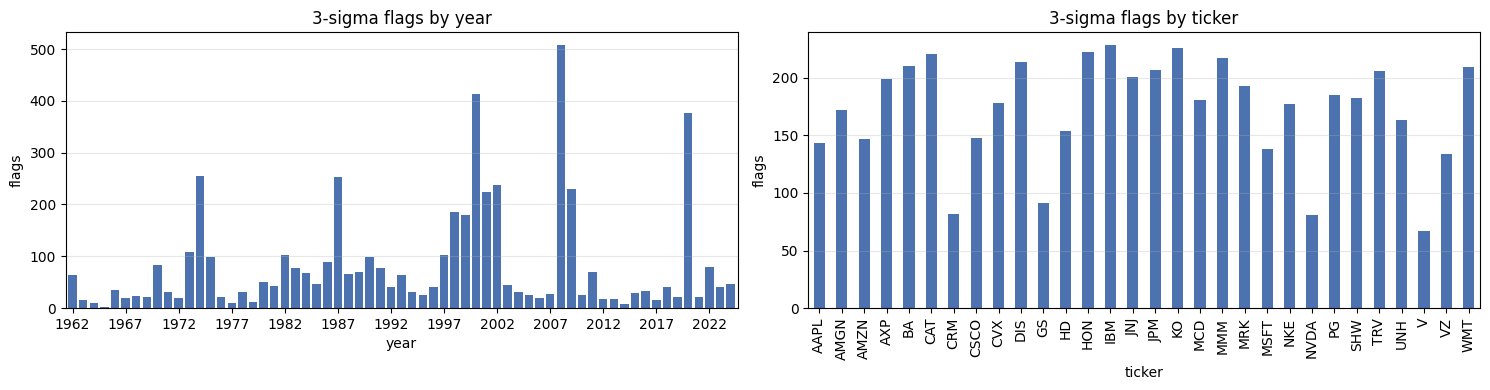

In [39]:
cleaned_hash_before = pd.util.hash_pandas_object(cleaned, index=False).sum()
investigation = hc.investigate_return_outliers(cleaned)
assert len(investigation) == cleaned["return_outlier_flag"].sum()
assert pd.util.hash_pandas_object(cleaned, index=False).sum() == cleaned_hash_before   # nothing modified

flag_year = investigation["ts"].str[:4].astype(int)
print(f"flags: {len(investigation):,} | positive: {(investigation['return'] > 0).sum():,} | "
      f"negative: {(investigation['return'] < 0).sum():,}")
print(f"zero volume: {(investigation['volume'] == 0).sum()} | volume <= 5% of 20-day median: "
      f"{(investigation['volume_ratio'] <= hc.LOW_VOLUME_RATIO).sum()} | volume < 20% of median: "
      f"{(investigation['volume_ratio'] < 0.2).sum()} | flat bars: {investigation['flat_bar'].sum()}")
flag_keys = investigation.set_index(["ticker", "ts"]).index
adj_info = cleaned.set_index(["ticker", "ts"]).loc[flag_keys]
print(f"adjustment association: factor changed > 1 pp on the day: "
      f"{(investigation['adj_return'] - investigation['return']).abs().gt(hc.ADJ_DIVERGENCE).sum()} | "
      f"adj_close rebuilt on the day: {int(adj_info['adj_close_repaired'].sum())} | "
      f"adj_factor_review_flag: {int(adj_info['adj_factor_review_flag'].sum())}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
flag_year.value_counts().sort_index().plot.bar(ax=axes[0], color="#4c72b0", width=0.8)
axes[0].set(title="3-sigma flags by year", xlabel="year", ylabel="flags")
axes[0].set_xticks(range(0, flag_year.nunique(), 5))
axes[0].set_xticklabels(sorted(flag_year.unique())[::5], rotation=0)
investigation["ticker"].value_counts().sort_index().plot.bar(ax=axes[1], color="#4c72b0")
axes[1].set(title="3-sigma flags by ticker", xlabel="ticker", ylabel="flags")
for ax in axes:
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

In [40]:
by_ticker = investigation.groupby("ticker").agg(flags=("return", "size"), positive=("return", lambda r: (r > 0).sum()),
                                                negative=("return", lambda r: (r < 0).sum()))
display(by_ticker.T)
print("flags by decade:", (flag_year // 10 * 10).value_counts().sort_index().to_dict())
cols = ["ticker", "ts", "prev_close", "close", "next_close", "return", "retained_1d", "retained_5d", "volume_ratio", "date_flag_count", "category"]
print("Largest positive returns:")
display(investigation.nlargest(5, "return")[cols])
print("Largest negative returns:")
display(investigation.nsmallest(5, "return")[cols])

ticker,AAPL,AMGN,AMZN,AXP,BA,CAT,CRM,CSCO,CVX,DIS,GS,HD,HON,IBM,JNJ,JPM,KO,MCD,MMM,MRK,MSFT,NKE,NVDA,PG,SHW,TRV,UNH,V,VZ,WMT
flags,143,172,147,199,210,221,82,148,178,214,91,154,222,228,201,207,226,181,217,193,138,177,81,185,182,206,163,67,134,209
positive,88,96,91,106,119,116,50,75,101,117,46,93,123,120,116,123,129,105,115,99,71,107,53,108,107,105,86,38,63,123
negative,55,76,56,93,91,105,32,73,77,97,45,61,99,108,85,84,97,76,102,94,67,70,28,77,75,101,77,29,71,86


flags by decade: {1960: 189, 1970: 673, 1980: 865, 1990: 847, 2000: 1759, 2010: 277, 2020: 566}
Largest positive returns:


,ticker,ts,prev_close,close,next_close,return,retained_1d,retained_5d,volume_ratio,date_flag_count,category
3955,NVDA,2000-03-07,0.12188,0.17357,0.1750,0.424106,1.023208,1.789200,4.247264,7,large_level_shift
4732,UNH,2008-10-13,17.35000,23.38000,22.9900,0.347550,0.943606,1.292300,1.652362,26,market_wide_move
420,AMZN,2001-11-26,0.45400,0.61050,0.5740,0.344714,0.791854,0.487365,7.378448,1,held_next_day
409,AMZN,2001-04-09,0.41850,0.55900,0.6005,0.335723,1.247392,1.954973,4.213523,1,persistent_move
62,AAPL,1997-08-06,0.17634,0.23493,0.2606,0.332256,1.361480,0.624525,12.467268,1,persistent_move


Largest negative returns:


,ticker,ts,prev_close,close,next_close,return,retained_1d,retained_5d,volume_ratio,date_flag_count,category
3066,MCD,1968-01-02,0.70988,0.174900,0.175670,-0.753620,0.996864,1.020200,12.086497,1,large_level_shift
98,AAPL,2000-09-29,0.95536,0.459820,0.433040,-0.518695,1.082058,1.203610,9.461535,1,large_level_shift
3997,NVDA,2004-08-06,0.12133,0.078584,0.082084,-0.352314,0.899677,0.752552,9.344780,1,persistent_move
4635,UNH,1987-10-20,0.14844,0.097656,0.125000,-0.342118,0.410449,0.729236,2.009721,16,market_wide_move
3986,NVDA,2002-07-31,0.13517,0.092250,0.083417,-0.317522,1.263476,1.586473,3.820581,2,persistent_move


In [41]:
summary_table = (investigation.groupby(["assessment", "category"]).size().rename("flags").reset_index())
summary_table["share"] = summary_table["flags"] / len(investigation)
display(summary_table)
display(investigation.groupby("assessment").size().rename("flags").to_frame().T)

clusters = (investigation.groupby("ts").agg(tickers_flagged=("ticker", "size"), mean_return=("return", "mean"))
            .query("tickers_flagged >= @hc.CLUSTER_MIN_TICKERS").sort_values("tickers_flagged", ascending=False))
print(f"{len(clusters)} dates with >= {hc.CLUSTER_MIN_TICKERS} tickers flagged, covering {clusters['tickers_flagged'].sum():,} flags; largest:")
display(clusters.head(10))

,assessment,category,flags,share
0,likely_data_error,low_volume_one_day_reversal,3,0.000580
1,likely_data_error,reversal_of_likely_error,3,0.000580
2,plausible_market_event,held_next_day,714,0.137944
3,plausible_market_event,market_wide_move,1512,0.292117
4,plausible_market_event,persistent_move,2654,0.512751
5,unresolved,adjustment_factor_change,18,0.003478
6,unresolved,large_level_shift,3,0.000580
7,unresolved,one_day_reversal,82,0.015842
8,unresolved,other,187,0.036128


assessment,likely_data_error,plausible_market_event,unresolved
flags,6,4880,290


159 dates with >= 5 tickers flagged, covering 1,515 flags; largest:


,tickers_flagged,mean_return
ts,,
2020-03-12,29,-0.098140
2020-03-16,28,-0.124501
2008-10-28,28,0.107868
2008-10-13,26,0.139611
2020-03-24,26,0.128104
1987-10-19,24,-0.207029
2008-10-15,22,-0.094399
2008-12-01,22,-0.091936
1988-01-08,21,-0.075909


**Representative examples** (one per category, with the measured evidence):

In [42]:
examples = (investigation.assign(abs_ret=investigation["return"].abs())
            .sort_values("abs_ret", ascending=False).groupby("category", sort=False).head(1))
examples[["ticker", "ts", "return", "category", "assessment", "evidence"]].reset_index(drop=True)

,ticker,ts,return,category,assessment,evidence
0,MCD,1968-01-02,-0.753620,large_level_shift,unresolved,"next close keeps 100% of the move, 5 days later 102%; volume 1208.6% of 20-day median;..."
1,NVDA,2004-08-06,-0.352314,persistent_move,plausible_market_event,"next close keeps 90% of the move, 5 days later 75%; volume 934.5% of 20-day median; 1 ..."
2,UNH,2008-10-13,0.347550,market_wide_move,plausible_market_event,"next close keeps 94% of the move, 5 days later 129%; volume 165.2% of 20-day median; 2..."
3,AMZN,2001-11-26,0.344714,held_next_day,plausible_market_event,"next close keeps 79% of the move, 5 days later 49%; volume 737.8% of 20-day median; 1 ..."
4,NVDA,2000-03-13,0.264858,other,unresolved,"next close keeps -29% of the move, 5 days later -71%; volume 469.3% of 20-day median; ..."
5,AXP,1984-08-21,0.189320,adjustment_factor_change,unresolved,"next close keeps 106% of the move, 5 days later 101%; volume 211.7% of 20-day median; ..."
6,AMZN,1999-01-11,0.152120,one_day_reversal,unresolved,"next close keeps 12% of the move, 5 days later -96%; volume 118.0% of 20-day median; 2..."
7,AXP,1972-12-15,0.147132,reversal_of_likely_error,likely_data_error,"next close keeps 100% of the move, 5 days later 100%; volume 123.9% of 20-day median; ..."
8,AXP,1975-08-04,-0.133574,low_volume_one_day_reversal,likely_data_error,"next close keeps 5% of the move, 5 days later 44%; volume 0.1% of 20-day median; 1 tic..."


**The three likely data errors**, with their neighbouring sessions:

In [43]:
suspects = investigation[investigation["category"] == "low_volume_one_day_reversal"]
ordered = cleaned.sort_values(["ticker", "ts"]).reset_index(drop=True)
for _, row in suspects.iterrows():
    i = ordered.index[(ordered["ticker"] == row["ticker"]) & (ordered["ts"] == row["ts"])][0]
    display(ordered.loc[i - 2:i + 2, ["ticker", "ts", "open", "high", "low", "close", "adj_close", "volume", "return_outlier_flag"]])

,ticker,ts,open,high,low,close,adj_close,volume,return_outlier_flag
28584,AXP,1972-12-12,4.63,4.63,4.63,4.63,1.56,672324,False
28585,AXP,1972-12-13,4.59,4.59,4.59,4.59,1.55,844816,False
28586,AXP,1972-12-14,4.01,4.01,4.01,4.01,1.35,0,True
28587,AXP,1972-12-15,4.60,4.60,4.60,4.60,1.56,979282,True
28588,AXP,1972-12-18,4.60,4.60,4.60,4.60,1.56,421049,False


,ticker,ts,open,high,low,close,adj_close,volume,return_outlier_flag
29247,AXP,1975-07-31,2.87,2.87,2.87,2.87,0.97064,1294061,False
29248,AXP,1975-08-01,2.77,2.77,2.77,2.77,0.93642,955399,False
29249,AXP,1975-08-04,2.41,2.43,2.40,2.40,0.80725,1553,True
29250,AXP,1975-08-05,2.75,2.75,2.75,2.75,0.93020,915008,True
29251,AXP,1975-08-06,2.75,2.75,2.75,2.75,0.93020,1093660,False


,ticker,ts,open,high,low,close,adj_close,volume,return_outlier_flag
125329,HD,1982-02-26,0.055969,0.055969,0.055969,0.055969,0.032189,387214,False
125330,HD,1982-03-01,0.055969,0.055969,0.055969,0.055969,0.032189,820125,False
125331,HD,1982-03-02,0.059808,0.059808,0.059808,0.059808,0.034606,22781,True
125332,HD,1982-03-03,0.055969,0.055969,0.055969,0.055969,0.032189,68344,True
125333,HD,1982-03-04,0.055969,0.055969,0.055969,0.055969,0.032189,318938,False


**Flat bars.** A flagged day with open = high = low = close looks suspicious, so all flat-bar flags are checked separately. The comparison that matters is with the base rate: before 1990 many records carry only a close, so flat bars are the normal format of old data.

In [44]:
decade = lambda ts: ts.str[:3] + "0s"
flat_flags = investigation[investigation["flat_bar"]]
all_flat = cleaned[hc.RAW_PRICES].nunique(axis=1) == 1
print(f"flat-bar flags: {len(flat_flags)} of {len(investigation):,} "
      f"({len(flat_flags) / len(investigation):.1%} of flags vs {all_flat.mean():.1%} of all rows)")
display(pd.DataFrame({"share of all rows": all_flat.groupby(decade(cleaned["ts"])).mean(),
                      "share of flagged rows": investigation["flat_bar"].groupby(decade(investigation["ts"])).mean()}).round(3).T)
display(flat_flags.groupby(["assessment", "category"]).size().rename("flags").to_frame().T)
print("by ticker:", flat_flags["ticker"].value_counts().to_dict())
print("by decade:", decade(flat_flags["ts"]).value_counts().sort_index().to_dict())

low_volume_flat = flat_flags[(flat_flags["volume"] == 0) | (flat_flags["volume_ratio"] <= 0.2)]
print(f"\nflat bars with volume <= 20% of the 20-day median: {len(low_volume_flat)}")
display(low_volume_flat[["ticker", "ts", "return", "retained_1d", "volume", "volume_ratio", "category"]])

known = {("AXP", "1972-12-14"), ("AXP", "1972-12-15"), ("AXP", "1975-08-04"), ("AXP", "1975-08-05"),
         ("HD", "1982-03-02"), ("HD", "1982-03-03")}
others = flat_flags[[(t, d) not in known for t, d in zip(flat_flags["ticker"], flat_flags["ts"])]]
candidates = others[(others["retained_1d"].abs() <= hc.REVERSAL_RETAINED) | (others["volume_ratio"] < 0.5)
                    | others["volume_ratio"].isna()]
print(f"other flat bars that reverse next day, trade below half of normal volume or lack a volume baseline: {len(candidates)}")
candidates[["ticker", "ts", "prev_close", "close", "next_close", "return", "retained_1d", "retained_5d",
            "volume_ratio", "date_flag_count", "category"]]

flat-bar flags: 254 of 5,176 (4.9% of flags vs 4.4% of all rows)


ts,1960s,1970s,1980s,1990s,2000s,2010s,2020s
share of all rows,0.179,0.237,0.044,0.0,0.0,0.0,0.0
share of flagged rows,0.164,0.245,0.067,0.0,0.0,0.0,0.0


assessment           likely_data_error                          plausible_market_event                                         unresolved                       
category   low_volume_one_day_reversal reversal_of_likely_error          held_next_day market_wide_move persistent_move large_level_shift one_day_reversal other
flags                                2                        3                     48               21             167                 1                3     9

by ticker: {'TRV': 63, 'AXP': 42, 'JNJ': 25, 'HD': 24, 'DIS': 17, 'MCD': 13, 'UNH': 12, 'CAT': 11, 'NKE': 10, 'PG': 7, 'AMGN': 7, 'SHW': 5, 'WMT': 5, 'IBM': 5, 'AAPL': 4, 'CVX': 3, 'JPM': 1}
by decade: {'1960s': 31, '1970s': 165, '1980s': 58}

flat bars with volume <= 20% of the 20-day median: 3


,ticker,ts,return,retained_1d,volume,volume_ratio,category
463,AXP,1972-12-14,-0.126362,-0.01611,0,0.000000,low_volume_one_day_reversal
1807,HD,1982-03-02,0.068592,0.00000,22781,0.044447,low_volume_one_day_reversal
1808,HD,1982-03-03,-0.064189,1.00000,68344,0.133343,reversal_of_likely_error


other flat bars that reverse next day, trade below half of normal volume or lack a volume baseline: 8


,ticker,ts,prev_close,close,next_close,return,retained_1d,retained_5d,volume_ratio,date_flag_count,category
143,AMGN,1983-06-20,0.34375,0.30208,0.30208,-0.121222,1.000000,1.845057,NaN,1,other
1824,HD,1982-12-09,0.29356,0.31551,0.28945,0.074772,-0.195532,-2.710658,1.892514,1,one_day_reversal
2448,JNJ,1970-02-04,1.15000,1.10000,1.15000,-0.043478,-0.000000,-0.769179,3.206630,1,one_day_reversal
2459,JNJ,1970-10-20,1.09000,1.15000,1.14000,0.055046,0.837010,1.161579,0.471338,1,other
4040,PG,1970-05-29,1.45000,1.52000,1.51000,0.048276,0.859997,0.290557,0.467389,2,other
4429,TRV,1974-09-06,2.03000,2.14000,2.05000,0.054187,0.185787,0.732464,1.619512,2,persistent_move
4431,TRV,1974-10-09,2.13000,1.97000,2.16000,-0.075117,-0.179108,-0.238258,5.704762,9,market_wide_move
4445,TRV,1975-05-12,3.58000,3.39000,3.56000,-0.053073,0.102732,-0.051151,1.477314,1,one_day_reversal


Neighbouring sessions of the most suspicious additional candidates:

In [45]:
for ticker, date in [("JNJ", "1970-02-04"), ("TRV", "1975-05-12"), ("HD", "1982-12-09"), ("AMGN", "1983-06-20")]:
    i = ordered.index[(ordered["ticker"] == ticker) & (ordered["ts"] == date)][0]
    first = ordered.index[ordered["ticker"] == ticker][0]
    display(ordered.loc[max(i - 2, first):i + 2, ["ticker", "ts", "open", "high", "low", "close", "volume", "return_outlier_flag"]])

,ticker,ts,open,high,low,close,volume,return_outlier_flag
169739,JNJ,1970-02-02,1.15,1.15,1.15,1.15,1612816,True
169740,JNJ,1970-02-03,1.15,1.15,1.15,1.15,2692816,False
169741,JNJ,1970-02-04,1.10,1.10,1.10,1.10,2793616,True
169742,JNJ,1970-02-05,1.15,1.15,1.15,1.15,1886416,True
169743,JNJ,1970-02-06,1.13,1.13,1.13,1.13,705600,False


,ticker,ts,open,high,low,close,volume,return_outlier_flag
317954,TRV,1975-05-08,3.63,3.63,3.63,3.63,345600,False
317955,TRV,1975-05-09,3.58,3.58,3.58,3.58,179200,False
317956,TRV,1975-05-12,3.39,3.39,3.39,3.39,325600,True
317957,TRV,1975-05-13,3.56,3.56,3.56,3.56,207200,False
317958,TRV,1975-05-14,3.69,3.69,3.69,3.69,224800,False


,ticker,ts,open,high,low,close,volume,return_outlier_flag
125526,HD,1982-12-07,0.27161,0.27161,0.27161,0.27161,3663225,False
125527,HD,1982-12-08,0.29356,0.29356,0.29356,0.29356,7636275,True
125528,HD,1982-12-09,0.31551,0.31551,0.31551,0.31551,8984925,True
125529,HD,1982-12-10,0.28945,0.28945,0.28945,0.28945,3471699,True
125530,HD,1982-12-13,0.27985,0.27985,0.27985,0.27985,1539919,False


,ticker,ts,open,high,low,close,volume,return_outlier_flag
11050,AMGN,1983-06-17,0.34375,0.34375,0.34375,0.34375,42936423,False
11051,AMGN,1983-06-20,0.30208,0.30208,0.30208,0.30208,7329672,True
11052,AMGN,1983-06-21,0.30208,0.30208,0.30208,0.30208,2280016,False
11053,AMGN,1983-06-22,0.31250,0.31250,0.31250,0.31250,5937656,False


* Flat bars are **not over-represented** among flags: 4.9% of flags against 4.4% of all rows, tracking the decade base rate (none after 1990).
* Only **two** flat-bar days combine a one-day reversal with near-zero volume — AXP 1972-12-14 and HD 1982-03-02, already classified as likely errors (with HD's return leg, the third flat bar at ≤ 20% volume). The third likely error, AXP 1975-08-04, is not a flat bar, so flatness is neither necessary nor sufficient.
* The other flat-bar reversals all trade on **normal or heavy volume**: JNJ 1970-02-04 (1.15 → 1.10 → 1.15 on 3.2x the 20-day median) and TRV 1975-05-12 (3.58 → 3.39 → 3.56 on 1.5x) are the most suspicious but stay **unresolved**; HD 1982-12-09 and TRV 1974-09-06 are the end of multi-day runs, and TRV 1974-10-09 is one of nine tickers flagged that day. AMGN 1983-06-20 is its second listed session, so it has no volume baseline; the move held. Two flagged flat bars sit next to the 1974–75 Sunday-dated rows; both are persistent moves on about twice normal volume, so the open question there is the date, not the price.
* **Conclusion:** the three existing events remain the only candidates with strong evidence. `flat_bar` is kept as a diagnostic column — it describes how a day was recorded, not whether its price is wrong — and is not a classification rule (a test pins this down). No prices or tables were changed.

**Findings**

* **Likely data errors — 3 days (6 flags including the return legs).** AXP 1972-12-14 (zero volume, flat bar, 4.59 → 4.01 → 4.60), AXP 1975-08-04 (1,553 shares against ~950,000 normally, full reversal) and HD 1982-03-02 (4% of normal volume, flat bar, full reversal). A close printed on zero or near-zero volume that is fully undone the next session is not credible as a traded price. **They are not repaired**: the moves (7–13%) are within the range of genuine moves, the low volume could itself be a recording error, and the same values appear in the reference table, so there is no independent confirmation. They stay in `ohlc_hw_cleaned` with `return_outlier_flag = 1`; whether to interpolate them (as for the TRV spikes) is a decision to take explicitly, not a consequence of the 3-sigma screen. None falls in the 2024 reporting window.
* **Plausible market events — about 94% of flags.** Most flags sit on days when many tickers moved together (1987-10-19, autumn 2008, March 2020) or are moves that held, on normal or heavy volume.
* **Unresolved — about 6% of flags.** Partial retracements, one-day reversals on normal volume, 18 days where the vendor adjustment factor changed, and three persistent level shifts above 40% (MCD 1968-01-02, AAPL 2000-09-29, NVDA 2000-03-07). They are kept and flagged; the data cannot distinguish their causes.

**Limitations.** The thresholds (75% reversal, 5% volume, 5 tickers, 40% move, 1 pp adjustment divergence) are judgment calls; the classification uses retrospective information (later prices), which is fine for data review but must never feed a trading signal; the 30-ticker universe makes "market-wide" a coarse proxy, especially before 1980 when fewer tickers trade; volume data is unreliable in the oldest decades; no external source was consulted.

**No data was changed by this investigation**: no repair was made, `ohlc_hw_cleaned` is unchanged (row hash asserted above), and the stored `return_outlier_flag` remains the review marker.

### Before / after statistics

In [46]:
stats = pd.concat({"before (de-duplicated)": unique[hc.VALUE_COLUMNS].describe().T,
                   "after (cleaned)": cleaned[hc.VALUE_COLUMNS].describe().T})
stats[["count", "mean", "std", "min", "50%", "max"]]

count          mean           std       min         50%           max
before (de-duplicated) open       368251.0  4.630877e+01  6.714301e+01  0.000000       19.89  6.042600e+02
                       high       368251.0  4.677120e+01  6.778907e+01  0.005208       20.09  6.086300e+02
                       low        368251.0  4.583977e+01  6.648920e+01  0.004801       19.67  5.978800e+02
                       close      368251.0  4.631671e+01  6.715469e+01  0.005208       19.90  6.054000e+02
                       adj_close  349877.0  5.171154e+01  1.950017e+02  0.002945       11.98  1.044251e+04
                       volume     368251.0  3.095142e+07  1.266145e+08  0.000000  4649600.00  9.276606e+09
after (cleaned)        open       368246.0  4.630935e+01  6.714328e+01  0.005208       19.89  6.042600e+02
                       high       368246.0  4.677178e+01  6.778934e+01  0.005208       20.09  6.086300e+02
                       low        368246.0  4.584034e+01  6.648947e+01  0.004801       19.67  5.978800e+02
                       close      368246.0  4.631729e+01  6.715496e+01  0.005208       19.91  6.054000e+02
                       adj_close  368246.0  3.727465e+01  6.358788e+01  0.002945       11.46  6.054000e+02
                       volume     368246.0  3.095184e+07  1.266153e+08  0.000000  4649648.00  9.276606e+09

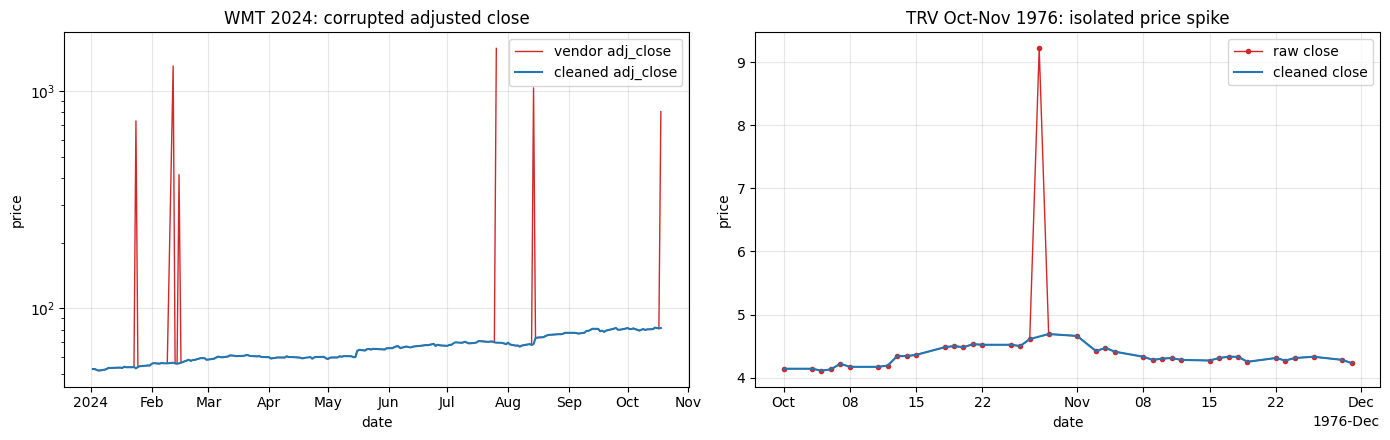

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
wmt_before = unique[(unique["ticker"] == "WMT") & (unique["ts"] >= "2024-01-01")]
wmt_after = cleaned[(cleaned["ticker"] == "WMT") & (cleaned["ts"] >= "2024-01-01")]
axes[0].plot(pd.to_datetime(wmt_before["ts"]), wmt_before["adj_close"], color="#d62728", lw=1, label="vendor adj_close")
axes[0].plot(pd.to_datetime(wmt_after["ts"]), wmt_after["adj_close"], color="#1f77b4", lw=1.5, label="cleaned adj_close")
axes[0].set(title="WMT 2024: corrupted adjusted close", ylabel="price", yscale="log")

trv_window = ("1976-10-01", "1976-11-30")
trv_before = unique[(unique["ticker"] == "TRV") & unique["ts"].between(*trv_window)]
trv_after = cleaned[(cleaned["ticker"] == "TRV") & cleaned["ts"].between(*trv_window)]
axes[1].plot(pd.to_datetime(trv_before["ts"]), trv_before["close"], color="#d62728", lw=1, marker=".", label="raw close")
axes[1].plot(pd.to_datetime(trv_after["ts"]), trv_after["close"], color="#1f77b4", lw=1.5, label="cleaned close")
axes[1].set(title="TRV Oct-Nov 1976: isolated price spike", ylabel="price")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    ax.set_xlabel("date")
fig.tight_layout()
plt.show()

### Save to the database
`ts` is stored as `YYYY-MM-DD` text and flags as 0/1 integers. `write_tables` refuses to overwrite `ohlc_hw`, `ohlc` or `market_caps`; re-running the notebook replaces only the six output tables. The quarantine and removed tables also keep the delivered date text in `ts_raw`.

In [48]:
outputs = {
    "ohlc_hw_cleaned": hc.to_sql_frame(cleaned),
    "ohlc_hw_quarantine": hc.to_sql_frame(result.quarantine),
    "ohlc_hw_repair_audit": hc.to_sql_frame(result.repair_audit),
    "ohlc_hw_ticker_audit": hc.to_sql_frame(result.ticker_audit),
    "ohlc_hw_removed": hc.to_sql_frame(result.removed),
    "ohlc_hw_quality_diagnosis": hc.to_sql_frame(diagnosis),
}
hc.write_tables(DB_PATH, outputs)
hc.table_counts(DB_PATH)

market_caps                    4342
ohlc                         368251
ohlc_hw                      397711
ohlc_hw_cleaned              368246
ohlc_hw_quality_diagnosis    114138
ohlc_hw_quarantine                5
ohlc_hw_removed               29460
ohlc_hw_repair_audit          28808
ohlc_hw_ticker_audit            150
Name: rows, dtype: int64

### Read back and verify

In [49]:
saved = hc.load_table(DB_PATH, "ohlc_hw_cleaned")
assert len(saved) == len(cleaned)
assert hc.validate_cleaned(saved)["passed"].all()

with hc.connect_readonly(DB_PATH) as con:
    non_iso = con.execute("SELECT COUNT(*) FROM ohlc_hw_cleaned WHERE ts NOT GLOB '[0-9][0-9][0-9][0-9]-[0-9][0-9]-[0-9][0-9]'").fetchone()[0]
    sample = pd.read_sql_query(
        "SELECT ts, ticker, close, adj_close FROM ohlc_hw_cleaned WHERE ticker = ? AND ts BETWEEN ? AND ? ORDER BY ts",
        con, params=("AAPL", "2024-06-01", "2024-06-07"))
assert non_iso == 0
print("non-ISO dates:", non_iso)
sample

non-ISO dates: 0


,ts,ticker,close,adj_close
0,2024-06-03,AAPL,194.03,193.81
1,2024-06-04,AAPL,194.35,194.13
2,2024-06-05,AAPL,195.87,195.64
3,2024-06-06,AAPL,194.48,194.26
4,2024-06-07,AAPL,196.89,196.66


In [50]:
saved_tables = {name: hc.load_table(DB_PATH, name) for name in outputs}
for name, frame in saved_tables.items():
    assert len(frame) == len(outputs[name]), name
    print(f"{name:28} {len(frame):>8,} rows")

raw_by_id = raw.set_index("source_rowid")
def matches_raw(table):
    # every withheld row must carry exactly the delivered values of its source row
    src = raw_by_id.loc[table["source_rowid"]]
    same = [(table[c].to_numpy() == src[c].to_numpy()) | (table[c].isna().to_numpy() & src[c].isna().to_numpy())
            for c in hc.VALUE_COLUMNS]
    return bool(np.all(same)) and (table["ts_raw"].to_numpy() == src["ts"].to_numpy()).all() \
        and (table["ticker_raw"].to_numpy() == src["ticker"].to_numpy()).all()

saved_removed, saved_quarantine = saved_tables["ohlc_hw_removed"], saved_tables["ohlc_hw_quarantine"]
saved_cleaned = saved_tables["ohlc_hw_cleaned"]
assert matches_raw(saved_removed) and matches_raw(saved_quarantine)
assert saved_cleaned["duplicate_copies_removed"].sum() + saved_quarantine["duplicate_copies_removed"].sum() \
    == (saved_removed["removal_reason"] == "exact_duplicate").sum() == 29_460
traced = set(saved_cleaned["source_rowid"]) | set(saved_quarantine["source_rowid"]) | set(saved_removed["source_rowid"])
assert traced == set(raw["source_rowid"]) and len(traced) == len(raw)
assert list(saved_tables["ohlc_hw_quality_diagnosis"].columns) == hc.ISSUE_COLUMNS
print("every raw source_rowid is in exactly one of cleaned / quarantine / removed;"
      " withheld rows match the raw table value for value")

ohlc_hw_cleaned               368,246 rows
ohlc_hw_quarantine                  5 rows
ohlc_hw_repair_audit           28,808 rows
ohlc_hw_ticker_audit              150 rows
ohlc_hw_removed                29,460 rows
ohlc_hw_quality_diagnosis     114,138 rows
every raw source_rowid is in exactly one of cleaned / quarantine / removed; withheld rows match the raw table value for value


In [51]:
fingerprints_after = {t: hc.table_fingerprint(DB_PATH, t) for t in ["ohlc_hw", "ohlc"]}
assert fingerprints_after == fingerprints_before, "a source table changed!"
counts_after = hc.table_counts(DB_PATH)
assert all(counts_after[t] == counts_before[t] for t in ["ohlc_hw", "ohlc", "market_caps"])
print("ohlc_hw and ohlc are byte-for-byte unchanged (row-hash fingerprints match).")
pd.concat({"before": counts_before, "after": counts_after}, axis=1).astype("Int64")

ohlc_hw and ohlc are byte-for-byte unchanged (row-hash fingerprints match).


,before,after
market_caps,4342,4342
ohlc,368251,368251
ohlc_hw,397711,397711
ohlc_hw_cleaned,368246,368246
ohlc_hw_quality_diagnosis,114138,114138
ohlc_hw_quarantine,5,5
ohlc_hw_removed,29460,29460
ohlc_hw_repair_audit,28808,28808
ohlc_hw_ticker_audit,150,150


## Summary

* **397,711** raw rows → **368,246** retained in `ohlc_hw_cleaned`; **29,460** exact duplicates removed (saved in `ohlc_hw_removed`, all credited in `duplicate_copies_removed`); **5** rows quarantined (`open = 0` on each ticker's first day). Every raw `source_rowid` appears in exactly one output table.
* **150** raw ticker labels normalized to **30** tickers; no conflicting duplicate keys.
* **3** confirmed TRV spike days interpolated between valid neighbours (raw OHLC and adjusted close).
* **28,796** adjusted closes rebuilt: 18,373 missing + 10,417 corrupted from validated date-matched reference factors, and 6 from agreeing neighbour factors where the reference factor itself was anomalous (3 TRV, AAPL, NKE, SHW).
* Kept and flagged for review: 5,176 3-sigma returns, 74 zero-volume days, 384 weekend-dated rows, 1 unconfirmed adjustment-factor anomaly (KO 1962-01-02).
* All 5,176 3-sigma flags were investigated: 4,880 plausible market events, 290 unresolved, 6 likely data errors (3 low-volume one-day reversals and their return legs) — kept and flagged, not repaired.
* Missing trading dates: **0** in the source delivery; **5** after cleaning, all labelled as withheld by cleaning.
* The pre-repair diagnosis (114,138 issue rows) is saved as `ohlc_hw_quality_diagnosis`.
* All validation checks pass on the saved table; the source tables are unchanged.